Consider a small travel agency with two employees, labeled as E1 and E2. Each employee has his/her own office. When a customer comes to agency (interarrivals are uniformly distributed between 7 and 30 minutes), she/he first goes to the office of E1 to get information on offered tours (uniformly distributed between 5 and 7 minutes). After talking to E1, she/he moves on to talk to E2 about financial aspects (uniformly distributed between 4 and 20 minutes). After talking to E2, with probability 30%, the customer decides not to buy anything and leaves the agency. With the remaining probability (70%), she/he buys a tour and goes back to E1 to get additional information (uniformly distributed between 3 and 7 minutes). A customer leaves the agency after getting additional information.

Customers form queue(s) at the office of each employee. In particular, arriving customers and customers that are visiting E1 for the second time form separate queues at the office of E1. Customers that are visiting E1 for the second time have priority over arriving customers. Both offices have infinite capacity for waiting customers.

Initially, there are three customers at the office of E1, one who has just started talking to E1 at time $t = 0$ and the other two waiting. The office of E2 is initially empty.

In [1]:
import numpy as np
import simpy as sp
import scipy.stats as stats

def generate_employee1_service_time():
    return(2 * np.random.rand() + 5)

def generate_employee2_service_time():
    return(16 * np.random.rand() + 4)

def generate_employee1_second_service_time():
    return(4 * np.random.rand() + 3)

def generate_interarrival_time():
    return(23 * np.random.rand() + 7)

In [2]:
#fisrt type of statistic we keep is tied to objects, moving customers. 2nd type of statistics is tied to sources, such as utilization. 
class MonitoredResource(sp.Resource): #base class resource
    def __init__(self, *args, **kwargs): #initialization
        super().__init__(*args, **kwargs)
#self.users gives #of customers using the system, self.queue gives #of customers waiting in queue
    def request(self, *args, **kwargs):
        self.data.append((self._env.now, len(self.users) + len(self.queue) + 1)) #when I request this resource I append the current clock (happens when an item arrives to the system or subsystem). len(self.users) is the number of users who are getting service at the current time, len(self.queue) number of customers waiting in the queue. +1 because I just arrives to the system, I should be counted. so in the list the current time is added by self._env.now, and the number of customers are added.
        return super().request(*args, **kwargs) #super is the resource, base class yukarda parantezde yazan

    def release(self, *args, **kwargs):
        self.data.append((self._env.now, len(self.users) + len(self.queue) - 1)) #departure from subystem or whole system, the server all the whole system. I do the opposite of init, I append time, number of customers in the system, both service and queue -1 one bc I just left.
        return super().release(*args, **kwargs)
    
class MonitoredPriorityResource(sp.PriorityResource): #base class priority resource
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

    def request(self, *args, **kwargs):
        self.data.append((self._env.now, len(self.users) + len(self.queue) + 1)) #daha çok ststistik tutmak istersen virgülle ayırarak yapabilirsin
        return super().request(*args, **kwargs)

    def release(self, *args, **kwargs):
        self.data.append((self._env.now, len(self.users) + len(self.queue) - 1))
        return super().release(*args, **kwargs)
    #I want to keep track of how many customers are in employee 1's office on ave and same for employee 2 

In [3]:
def customer(env, name, employee1, employee2):
    employee1_request = employee1.request(0)
    yield employee1_request
    
    employee1_time = generate_employee1_service_time()
    yield env.timeout(employee1_time)
    
    employee1.release(employee1_request)
    
    employee2_request = employee2.request()
    yield employee2_request
    
    employee2_time = generate_employee2_service_time()
    yield env.timeout(employee2_time)
    
    employee2.release(employee2_request)
    
    if np.random.rand() < 0.3:
        second_time = False
    else:
        second_time = True
        employee1_request = employee1.request(-1)
        yield employee1_request

        employee1_time = generate_employee1_second_service_time()
        yield env.timeout(employee1_time)

        employee1.release(employee1_request)
    
def setup(env, employee1, employee2):
    for i in np.arange(1, 4):
        env.process(customer(env, "Customer#{:d}".format(i), employee1, employee2))
    
    while True:
        interarrival_time = generate_interarrival_time()
        yield env.timeout(interarrival_time)
        i = i + 1 #we will replicate the simulation once 
        env.process(customer(env, "Customer#{:d}".format(i), employee1, employee2))

np.random.seed(344)
env = sp.Environment()
employee1 = MonitoredPriorityResource(env, 1) #another difference from previous is that I took employee 1 and 2 outside of the setup function, because I would like to print their statistics at the end.
employee2 = MonitoredResource(env, 1)
env.process(setup(env, employee1, employee2))
env.run(until = 48)

employee1.data.append((48, len(employee1.users) + len(employee1.queue)))
employee2.data.append((48, len(employee2.users) + len(employee2.queue)))

In [4]:
print(employee1.data)
print(employee2.data)
#at time 0 3 arrivals accured, at time 6.53 one of them finished getting service and went to new stage, 2 (employee 2). at time 11.57 a departure, number decreased to 1 anf at 14 number increased to 2 so arrival.
#employee 2 got the first arrival at 6.53.

[(0, 0), (0, 1), (0, 2), (0, 3), (6.538743104414255, 2), (11.575621197936826, 1), (14.219374210331665, 2), (15.389217135025113, 3), (17.025215233181527, 2), (20.50074307634542, 1), (25.963855689878176, 0), (27.27125198926017, 1), (28.901955536784822, 2), (32.75537184351757, 3), (33.134267546526345, 2), (39.462575779652624, 1), (41.45656231351899, 2), (42.04318858595157, 3), (45.8727306516299, 2), (48, 2)]
[(0, 0), (6.538743104414255, 1), (11.575621197936826, 2), (15.389217135025113, 1), (17.025215233181527, 2), (25.963855689878176, 3), (27.27125198926017, 2), (32.75537184351757, 1), (41.45656231351899, 0), (45.8727306516299, 1), (48, 1)]


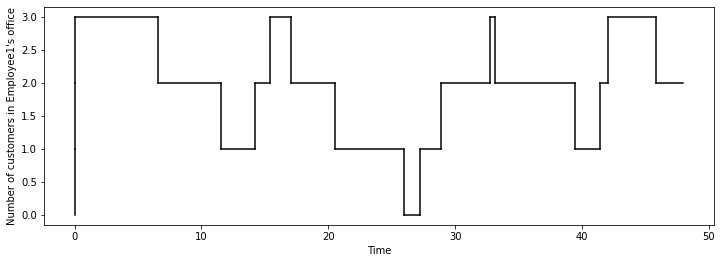

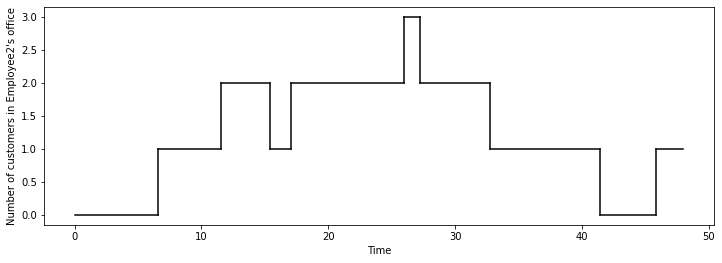

In [5]:
#lets draw number of customers vs time
import matplotlib.pyplot as plt

plt.figure(figsize = (12, 4))
for i in range(len(employee1.data) - 1):
    plt.plot([employee1.data[i][0], employee1.data[i + 1][0]], #[employee1.data[i][0]] gives the time, (a,b) den a yı veriyor 
             [employee1.data[i][1], employee1.data[i][1]], "k-") #[employee1.data[i][1]] gives the number of employees hani data (a,b) şeklinde ya b veriyor
    #we drew departures and arrivals so this part gives jumps
    plt.plot([employee1.data[i + 1][0], employee1.data[i + 1][0]], #connects the horizontal lines
             [employee1.data[i][1], employee1.data[i + 1][1]], "k-") #connects the vertical lines
plt.ylabel("Number of customers in Employee1's office")
plt.xlabel("Time")
plt.show()

plt.figure(figsize = (12, 4))
for i in range(len(employee2.data) - 1):
    plt.plot([employee2.data[i][0], employee2.data[i + 1][0]],
             [employee2.data[i][1], employee2.data[i][1]], "k-")
    plt.plot([employee2.data[i + 1][0], employee2.data[i + 1][0]],
             [employee2.data[i][1], employee2.data[i + 1][1]], "k-")
plt.ylabel("Number of customers in Employee2's office")
plt.xlabel("Time")
plt.show()

In [6]:
average_count1 = 0 #we are going to calculate the area under the curve and divide it by the total time
for i in range(len(employee1.data) - 1):
    average_count1 += (employee1.data[i + 1][0] - employee1.data[i][0]) * employee1.data[i][1] #base* height
average_count1 /= 48 #divide by simulation time, we take time based average
print(average_count1)

1.959100638857816


In [7]:
average_count2 = 0
for i in range(len(employee2.data) - 1):
    average_count2 += (employee2.data[i + 1][0] - employee2.data[i][0]) * employee2.data[i][1]
average_count2 /= 48
print(average_count2)

1.2061716125891908
